# Week 3：生存分析

目标：
1. 理解删失（censoring）、Kaplan–Meier、log-rank、Cox 比例风险、C-index；
2. 画 OS/PFS 的 KM 曲线，按 Response 分组做 log-rank；
3. 用 CoxPHFitter 拟合“临床特征”和“临床+基因组”两个模型；
4. 在训练集/测试集分别计算 C-index；
5. 结果写入 results/survival_metrics.csv。

In [1]:
# 导入依赖、定位路径、读取数据
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test
from lifelines.utils import concordance_index

import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 自动向上找到包含 data/ 的项目根目录
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent

RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(ROOT / "data/raw/chowell_train.csv")
test = pd.read_csv(ROOT / "data/raw/chowell_test.csv")

print("ROOT:", ROOT)
print("train:", train.shape)
print("test :", test.shape)

ROOT: d:\TJH课题工作内容\clinicaltransformer\studyplan
train: (1184, 28)
test : (295, 28)


In [2]:
# 定义生存分析用的特征
RESPONSE = "Response (1:Responder; 0:Non-responder)"

# 临床特征（10 个）
CLINICAL_FEATURES = [
    "Age",
    "Sex (1:Male; 0:Female)",
    "BMI",
    "Stage (1:IV; 0:I-III)",
    "NLR",
    "Platelets",
    "HGB",
    "Albumin",
    "Drug (1:Combo; 0:PD1/PDL1orCTLA4)",
    "Chemo_before_IO (1:Yes; 0:No)",
]

# 基因组/免疫特征（6 个）
GENOMIC_FEATURES = [
    "TMB",
    "FCNA",
    "HED",
    "HLA_LOH",
    "MSI (1:Unstable; 0:Stable_Indeterminate)",
    "MSI_SCORE",
]

# 癌种是类别变量，做 one-hot
CATEGORICAL_FEATURES = [
    "Cancer_type_grouped_2",
]

# 注意：Response、OS、PFS 都是结局，不能作为 Cox 的输入特征
print("clinical:", len(CLINICAL_FEATURES))
print("genomic :", len(GENOMIC_FEATURES))
print("full    :", len(CLINICAL_FEATURES) + len(GENOMIC_FEATURES) + len(CATEGORICAL_FEATURES))

clinical: 10
genomic : 6
full    : 17


In [3]:
# 预处理（训练集拟合，测试集只trandform）
def fit_transform_survival(train_df, test_df, numeric_features):#类别特征 CATEGORICAL_FEATURES 没有作为参数，而是直接用全局变量——这意味着两个模型都会自动带上癌种特征
    """
    在训练集上拟合预处理器，返回训练/测试的全数值 DataFrame。
    注意：预处理器只在训练集上 fit，测试集只 transform，
    避免把测试集信息泄漏进训练过程。
    """
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    prep = ColumnTransformer([
        ("num", num_pipe, numeric_features),
        ("cat", cat_pipe, CATEGORICAL_FEATURES),
    ], remainder="drop")

    cols = numeric_features + CATEGORICAL_FEATURES #把两类列名拼起来作为从DataFrame取子表的清单

    X_train = prep.fit_transform(train_df[cols])#fit从训练集学习每个数值列的中位数/均值/标准差/，每个类别列出现的类别；；transform用学到的参数变化训练集
    X_test = prep.transform(test_df[cols])# 防泄漏设计，测试集只使用训练集学到的中位数/均值/标准差/类别列表，而不是用自己的统计量，防止泄露
    names = prep.get_feature_names_out()# 取出输出的列名，因为变换后列会变多(one-hot展开)，需要知道每列叫什么

    train_out = pd.DataFrame(X_train, columns=names, index=train_df.index)#index是为了保留原索引，因为后面生存分析用的标签需要与特征行一一对应，索引被打乱会导致样本错位
    test_out = pd.DataFrame(X_test, columns=names, index=test_df.index)

    return train_out, test_out, prep
# train_out训练特征，test_out测试特征
# prep拟合好的预处理器，以后新数据可以直接prep.transform()，或joblib.dump保存


# 模型 1：临床 + 癌种
X_train_clin, X_test_clin, prep_clin = fit_transform_survival(
    train, test, CLINICAL_FEATURES
)

# 模型 2：临床 + 基因组/免疫 + 癌种
X_train_full, X_test_full, prep_full = fit_transform_survival(
    train, test, CLINICAL_FEATURES + GENOMIC_FEATURES
)

print("clinical train:", X_train_clin.shape)
print("full train    :", X_train_full.shape)

clinical train: (1184, 26)
full train    : (1184, 32)


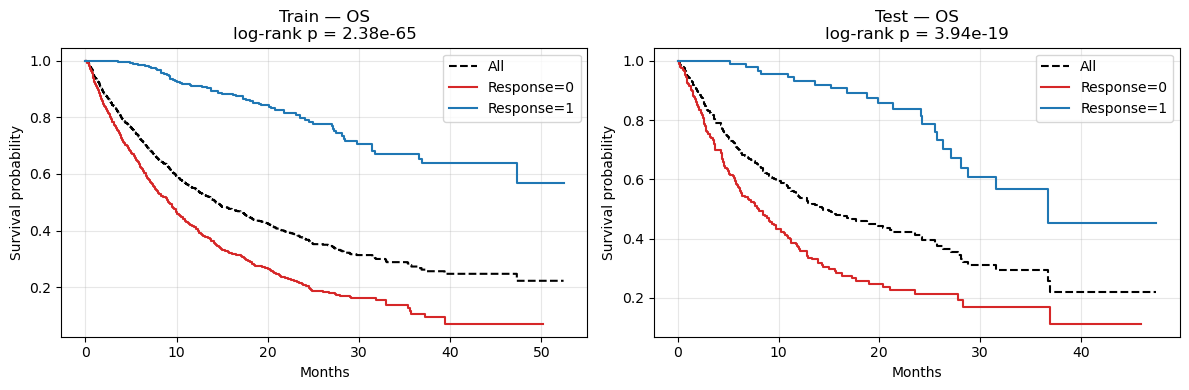

In [4]:
#KM曲线+log-rank(OS)
#KM曲线详见机器学习笔记KM曲线部分

#本部分画一张双面板KM图
#左：训练集OS的KM曲线
#右：测试集OS的KM曲线
#主要回答：治疗响应者是否比未响应者生存更久？这个现象在训练集和测试集是否一致？
def plot_km_by_response(df, time_col, event_col, title, ax):
    """
    在指定 axes 上画：
    - 总体 KM（黑色虚线）
    - Response=0 / Response=1 两组 KM
    - 两组之间的 log-rank p 值

    注意：Response 是治疗后变量，这里的 KM 只描述关联，
    不能当作“基线预测模型”。
    """
    # 总体 KM
    kmf_all = KaplanMeierFitter() #创建一个KM估计器
    kmf_all.fit(df[time_col], df[event_col], label="All") #fit(时间、事件)，第一个位置参数为durations(生存时间)，第二个位置参数为event_observed(1/True表示事件发生，0/False表示删失)
    kmf_all.plot_survival_function(ax=ax, color="black", linestyle="--", ci_show=False)# ci_show表示是否画95%置信带

    # 按 Response 分组
    for label, color in [(0, "tab:red"), (1, "tab:blue")]: #tab:red / tab:blue 是 matplotlib 的默认调色板名称，比写十六进制色值更易读。
        mask = df[RESPONSE] == label #RESPONSE为全局常量，如果要修改需要在RESPONSE处修改
        kmf = KaplanMeierFitter()
        kmf.fit(
            df.loc[mask, time_col],
            df.loc[mask, event_col],
            label=f"Response={label}",
        )
        kmf.plot_survival_function(ax=ax, color=color, ci_show=False) 

    # log-rank 检验，检验两条曲线有没有差异
    mask = df[RESPONSE] == 1
    lr = logrank_test(
        df.loc[mask, time_col],
        df.loc[~mask, time_col],#~mask取反，即Response=0的布尔序列
        event_observed_A=df.loc[mask, event_col],
        event_observed_B=df.loc[~mask, event_col],
    )

    ax.set_title(f"{title}\nlog-rank p = {lr.p_value:.3g}")
    ax.set_xlabel("Months")
    ax.set_ylabel("Survival probability")
    ax.grid(alpha=0.3)


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_km_by_response(train, "OS_Months", "OS_Event", "Train — OS", axes[0])
plot_km_by_response(test, "OS_Months", "OS_Event", "Test — OS", axes[1])

fig.tight_layout() # 防止标题/轴标签被裁
fig.savefig(RESULTS / "w03_km_os_by_response.png", dpi=300, bbox_inches="tight")
plt.show()

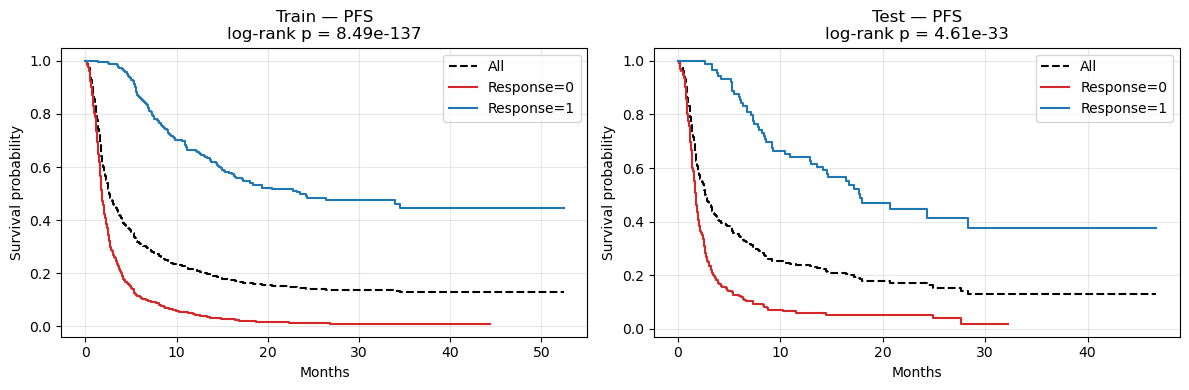

In [ ]:
#KM曲线+log-rank(PFS)
#OS与PFS区别见机器学习笔记相关部分
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_km_by_response(train, "PFS_Months", "PFS_Event", "Train — PFS", axes[0])
plot_km_by_response(test, "PFS_Months", "PFS_Event", "Test — PFS", axes[1])

fig.tight_layout()
fig.savefig(RESULTS / "w03_km_pfs_by_response.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#拟合Cox模型并计算C-index
#Cox模型与C-index相关内容见机器学习笔记部分
# 这一部分的目的是做生存模型的"训练-测试评估"闭环，共：
# 2 个终点：OS（总生存）、PFS（无进展生存）× 2 个特征集：Cox clinical（临床+癌种）、Cox full（临床+基因组+癌种）= 4 个 Cox 模型
# 每个模型计算训练集和测试集的C-index(测试集才是对泛化能力的诚实估计)

#定义函数

def fit_cox_model(X_train, train_df, time_col, event_col, penalizer=0.01):
    """
    在训练集上拟合 Cox 比例风险模型。

    参数
    ----
    X_train   : 预处理后的训练特征（全数值）
    train_df  : 原始训练表，用来取 time/event
    time_col  : 时间列，例如 OS_Months
    event_col : 事件列，1=事件发生，0=删失
    penalizer : 轻微 L2 正则，帮助收敛；设为 0 则是不惩罚 Cox
    """
    #将时间/事件拼进特征表中
    df_train = X_train.copy() #避免修改原表
    df_train[time_col] = train_df[time_col].values #.values取numpy数组，按照位置赋给df_train行
    df_train[event_col] = train_df[event_col].values

    #创建Cox模型
    cph = CoxPHFitter(penalizer=penalizer)

    #拟合
    cph.fit(df_train, duration_col=time_col, event_col=event_col)#lifelines自动将duration_col和event_col列从协变量中排除，不对它们估计系数

    # 训练集 C-index：偏乐观，只用于参考
    train_c = cph.score(df_train, scoring_method="concordance_index")

    #返回指标：
    #cph：拟合好的模型，可查summary、预测风险、画图
    #df_train：拼好时间/事件数据，方便后续复现/检查
    #train_c：训练集C-index
    return cph, df_train, train_c


def evaluate_cox(cph, X_test, test_df, time_col, event_col):
    """
    在测试集上计算 C-index。
    这才是对模型泛化能力的诚实估计。
    """
    #拼测试集
    df_test = X_test.copy()
    df_test[time_col] = test_df[time_col].values
    df_test[event_col] = test_df[event_col].values

    #用已经拟合的模型评估
    #没有再fit，直接在测试集评估
    test_c = cph.score(df_test, scoring_method="concordance_index")

    return test_c, df_test

# 主循环

rows = []
fitted = {}

# 对 OS 和 PFS 分别建模
for endpoint, time_col, event_col in [
    ("OS", "OS_Months", "OS_Event"),
    ("PFS", "PFS_Months", "PFS_Event"),
]:
    # 两个模型：临床 vs 临床+基因组
    for model_name, X_train, X_test in [
        ("Cox clinical", X_train_clin, X_test_clin),
        ("Cox full", X_train_full, X_test_full),
    ]:
        cph, df_train, train_c = fit_cox_model(
            X_train, train, time_col, event_col
        )
        test_c, df_test = evaluate_cox(
            cph, X_test, test, time_col, event_col
        )

        fitted[(endpoint, model_name)] = cph

        rows.append({
            "model": model_name,
            "endpoint": endpoint,
            "split": "train",
            "c_index": train_c,
            "notes": (
                f"n={len(df_train)}; "
                f"events={int(df_train[event_col].sum())}; "
                "penalizer=0.01"
            ),
        })
        rows.append({
            "model": model_name,
            "endpoint": endpoint,
            "split": "test",
            "c_index": test_c,
            "notes": (
                f"n={len(df_test)}; "
                f"events={int(df_test[event_col].sum())}; "
                "penalizer=0.01"
            ),
        })

        print(
            f"{endpoint:3s} | {model_name:13s} | "
            f"train C-index={train_c:.4f} | test C-index={test_c:.4f}"
        )